# 00 - Data Acquisition & Cleaning

Pulls daily prices for both pairs, cleans them, and saves everything downstream notebooks need so nothing re-fetches from yfinance. Also fixes the train/holdout split up front: the last ~2 years are set aside now and not touched again until notebook 06.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

DATA_DIR = "../data"
os.makedirs(DATA_DIR, exist_ok=True)

FX_TICKERS = {"AUD": "AUDUSD=X", "NZD": "NZDUSD=X"}
COMM_TICKERS = {"WTI": "CL=F", "BRENT": "BZ=F"}

START = "2000-01-01"
END = "2026-08-14"

# last ~2 years held out, not touched again until notebook 06
HOLDOUT_START = "2024-08-15"

### Fetch raw series

In [2]:
def fetch_series(ticker):
    df = yf.download(ticker, start=START, end=END, progress=False, auto_adjust=True)
    s = df["Close"]
    if isinstance(s, pd.DataFrame):
        s = s.iloc[:, 0]
    s.name = ticker
    return s

fx_raw = {name: fetch_series(tkr) for name, tkr in FX_TICKERS.items()}
comm_raw = {name: fetch_series(tkr) for name, tkr in COMM_TICKERS.items()}

fx_df = pd.DataFrame(fx_raw)
comm_df = pd.DataFrame(comm_raw)

print("FX raw:", fx_df.index.min().date(), "->", fx_df.index.max().date(), fx_df.shape)
print("Commodities raw:", comm_df.index.min().date(), "->", comm_df.index.max().date(), comm_df.shape)
print("\nNaN counts before cleaning (different tickers start on different dates):")
print(fx_df.isna().sum())
print(comm_df.isna().sum())

FX raw: 2003-12-01 -> 2026-08-13 (5891, 2)
Commodities raw: 2000-08-23 -> 2026-08-13 (6522, 2)

NaN counts before cleaning (different tickers start on different dates):
AUD    625
NZD      0
dtype: int64
WTI         1
BRENT    1783
dtype: int64


### Clean and derive spreads

AUDUSD=X and NZDUSD=X don't start on the same date, so an inner join gives the window both legs actually have.

In [3]:
fx_df = fx_df.dropna(how="any").sort_index()
comm_df = comm_df.dropna(how="any").sort_index()

# AUD/NZD cross = value of 1 AUD in NZD terms
fx_df["AUDNZD"] = fx_df["AUD"] / fx_df["NZD"]

# spread as a difference, not a ratio - stays defined even if a leg goes non-positive (see below)
comm_df["WTI_BRENT_SPREAD"] = comm_df["WTI"] - comm_df["BRENT"]

print("FX effective start:", fx_df.index.min().date())
print("Commodities effective start:", comm_df.index.min().date())

FX effective start: 2006-05-16
Commodities effective start: 2007-07-30


### Data quality checks

Non-positive prices, return outliers, and missing business days - the usual before trusting a series for anything downstream.

In [4]:
for name, series in [("WTI", comm_df["WTI"]), ("BRENT", comm_df["BRENT"])]:
    non_pos = series[series <= 0]
    if len(non_pos):
        print(f"{name}: {len(non_pos)} non-positive price day(s):")
        print(non_pos)

WTI: 1 non-positive price day(s):
Date
2020-04-20   -37.630001
Name: WTI, dtype: float64


In [5]:
# simple returns, not log - log is undefined once WTI goes negative
def flag_jumps(series, z_thresh=6.0):
    ret = series.pct_change().dropna()
    ret = ret.replace([np.inf, -np.inf], np.nan).dropna()
    z = (ret - ret.mean()) / ret.std()
    return z[z.abs() > z_thresh]

jumps = {
    "AUD": flag_jumps(fx_df["AUD"]),
    "NZD": flag_jumps(fx_df["NZD"]),
    "WTI": flag_jumps(comm_df["WTI"]),
    "BRENT": flag_jumps(comm_df["BRENT"]),
}
for name, j in jumps.items():
    print(f"{name}: {len(j)} jump day(s) -> {list(j.index.date)}")

AUD: 8 jump day(s) -> [datetime.date(2008, 10, 6), datetime.date(2008, 10, 8), datetime.date(2008, 10, 10), datetime.date(2008, 10, 13), datetime.date(2008, 10, 15), datetime.date(2008, 10, 24), datetime.date(2008, 10, 28), datetime.date(2025, 4, 7)]
NZD: 2 jump day(s) -> [datetime.date(2008, 10, 24), datetime.date(2008, 10, 28)]
WTI: 3 jump day(s) -> [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21), datetime.date(2020, 4, 22)]
BRENT: 5 jump day(s) -> [datetime.date(2019, 9, 16), datetime.date(2020, 3, 9), datetime.date(2020, 4, 2), datetime.date(2020, 4, 21), datetime.date(2026, 4, 1)]


In [6]:
def missing_bdays(series):
    full_range = pd.bdate_range(series.index.min(), series.index.max())
    return full_range.difference(series.index)

fx_missing = missing_bdays(fx_df["AUD"])
comm_missing = missing_bdays(comm_df["WTI"])

print(f"FX: {len(fx_missing)} missing business days out of "
      f"{len(pd.bdate_range(fx_df.index.min(), fx_df.index.max()))} "
      f"({100*len(fx_missing)/len(pd.bdate_range(fx_df.index.min(), fx_df.index.max())):.2f}%)")
print(f"Commodities: {len(comm_missing)} missing business days out of "
      f"{len(pd.bdate_range(comm_df.index.min(), comm_df.index.max()))} "
      f"({100*len(comm_missing)/len(pd.bdate_range(comm_df.index.min(), comm_df.index.max())):.2f}%)")

FX: 17 missing business days out of 5283 (0.32%)
Commodities: 231 missing business days out of 4969 (4.65%)


### Plot

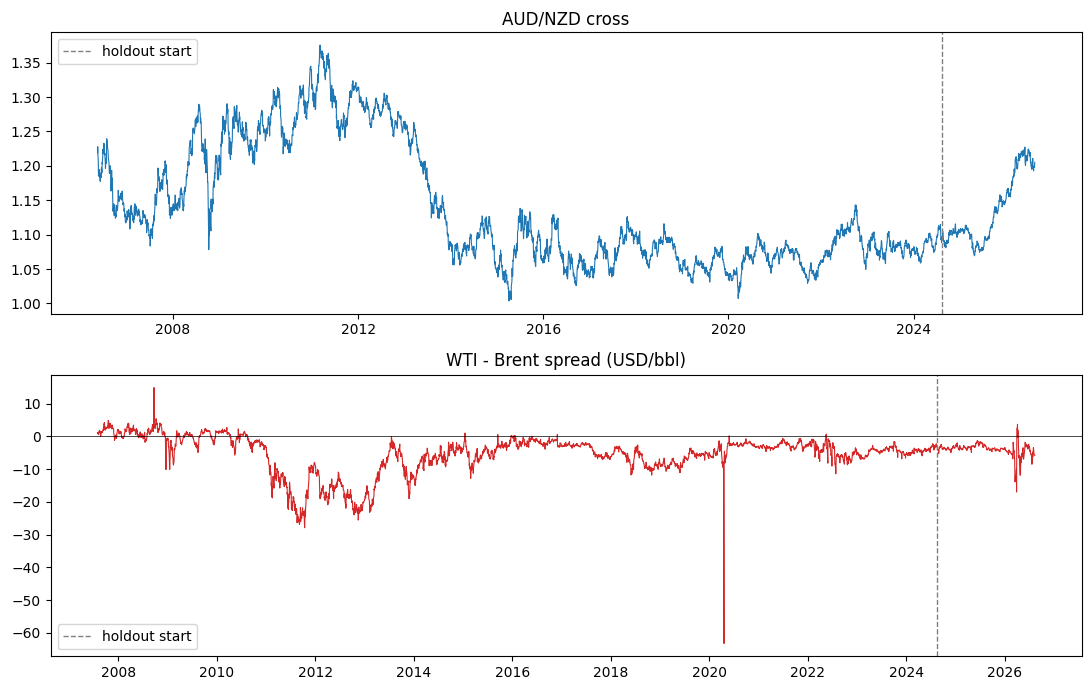

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)

axes[0].plot(fx_df.index, fx_df["AUDNZD"], color="#1f77b4", linewidth=0.8)
axes[0].axvline(pd.Timestamp(HOLDOUT_START), color="grey", linestyle="--", linewidth=1, label="holdout start")
axes[0].set_title("AUD/NZD cross")
axes[0].legend()

axes[1].plot(comm_df.index, comm_df["WTI_BRENT_SPREAD"], color="#d62728", linewidth=0.8)
axes[1].axvline(pd.Timestamp(HOLDOUT_START), color="grey", linestyle="--", linewidth=1, label="holdout start")
axes[1].axhline(0, color="black", linewidth=0.5)
axes[1].set_title("WTI - Brent spread (USD/bbl)")
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(DATA_DIR, "00_raw_series_overview.png"), dpi=120)
plt.show()

### Train / holdout split

Nothing from notebook 01 onward should see the holdout period until notebook 06.

In [8]:
train_fx = fx_df[fx_df.index < HOLDOUT_START]
holdout_fx = fx_df[fx_df.index >= HOLDOUT_START]
train_comm = comm_df[comm_df.index < HOLDOUT_START]
holdout_comm = comm_df[comm_df.index >= HOLDOUT_START]

print("FX train/holdout:", train_fx.shape, holdout_fx.shape)
print("Commodities train/holdout:", train_comm.shape, holdout_comm.shape)

FX train/holdout: (4750, 3) (516, 3)
Commodities train/holdout: (4236, 3) (502, 3)


### Save

In [9]:
fx_df.to_parquet(os.path.join(DATA_DIR, "fx_aud_nzd.parquet"))
comm_df.to_parquet(os.path.join(DATA_DIR, "comm_wti_brent.parquet"))

config = {
    "start": START,
    "end": END,
    "holdout_start": HOLDOUT_START,
    "fx_tickers": FX_TICKERS,
    "comm_tickers": COMM_TICKERS,
    "fx_effective_start": str(fx_df.index.min().date()),
    "comm_effective_start": str(comm_df.index.min().date()),
}
with open(os.path.join(DATA_DIR, "config.json"), "w") as f:
    json.dump(config, f, indent=2)

print("Saved fx_aud_nzd.parquet, comm_wti_brent.parquet, config.json to", DATA_DIR)

Saved fx_aud_nzd.parquet, comm_wti_brent.parquet, config.json to ../data


In [10]:
notes = f"""# Data quality notes

## Sources
- FX: yfinance `AUDUSD=X`, `NZDUSD=X` (effective common start: {fx_df.index.min().date()})
- Commodities: yfinance `CL=F` (WTI), `BZ=F` (Brent) continuous futures (effective common start: {comm_df.index.min().date()})

Tickers within a pair start on different dates in yfinance, so the effective start above
(after the inner join) is later than either individual ticker's raw history.

## WTI negative price, 2020-04-20
WTI (CL=F) closed at -37.63 USD/bbl on 2020-04-20 - the COVID demand collapse / Cushing storage
crunch. Brent didn't go negative, so this is a real dislocation between the two legs, not a data
error. Return calcs use simple returns rather than log returns because of this (log is undefined
for non-positive prices), and the spread is a difference rather than a ratio for the same reason.

Worth checking in notebook 01 whether this date coincides with any instability in the rolling
cointegration test.

## Jump days (|z| > 6 on simple returns)
{chr(10).join(f"- {k}: {list(v.index.date)}" for k, v in jumps.items() if len(v))}

## Missing business days
- FX: {len(fx_missing)} / {len(pd.bdate_range(fx_df.index.min(), fx_df.index.max()))}
- Commodities: {len(comm_missing)} / {len(pd.bdate_range(comm_df.index.min(), comm_df.index.max()))}

Commodities have a higher gap rate, consistent with CME holiday closures not lining up with FX's
near-continuous trading. Rolling-window notebooks should check the two legs are aligned before
computing spreads.

## Train / holdout split
- Train: start -> {HOLDOUT_START}
- Holdout: {HOLDOUT_START} -> {END} (untouched until notebook 06)
"""

with open(os.path.join(DATA_DIR, "data_quality_notes.md"), "w") as f:
    f.write(notes)

print(notes)

# Data quality notes

## Sources
- FX: yfinance `AUDUSD=X`, `NZDUSD=X` (effective common start: 2006-05-16)
- Commodities: yfinance `CL=F` (WTI), `BZ=F` (Brent) continuous futures (effective common start: 2007-07-30)

Tickers within a pair start on different dates in yfinance, so the effective start above
(after the inner join) is later than either individual ticker's raw history.

## WTI negative price, 2020-04-20
WTI (CL=F) closed at -37.63 USD/bbl on 2020-04-20 - the COVID demand collapse / Cushing storage
crunch. Brent didn't go negative, so this is a real dislocation between the two legs, not a data
error. Return calcs use simple returns rather than log returns because of this (log is undefined
for non-positive prices), and the spread is a difference rather than a ratio for the same reason.

Worth checking in notebook 01 whether this date coincides with any instability in the rolling
cointegration test.

## Jump days (|z| > 6 on simple returns)
- AUD: [datetime.date(2008, 10, 6), 

Notebook 01 picks up from `fx_aud_nzd.parquet`, `comm_wti_brent.parquet`, and `config.json` - loading the config rather than hardcoding dates again.